# Part 3: PCA Meets CNNs — Analyzing and Initializing Deep Representations

## CS 437: Deep Learning — Spring 2026

---

### 🎯 Assignment Overview

In this assignment, you will explore the fascinating intersection of **Principal Component Analysis (PCA)** and **Convolutional Neural Networks (CNNs)**. You will:

1. **Build** a CNN from scratch with hooks to extract intermediate representations
2. **Analyze** CNN latent spaces using PCA visualization
3. **Initialize** CNN filters using PCA eigenvectors ("eigenfilters")
4. **Ablate** the effect of PCA component budget on classification performance

**Dataset**: Fashion-MNIST (70,000 grayscale 28×28 images, 10 classes)

**Estimated Time**: ~3.5 hours

---

### 📋 Grading Rubric

| Section | Points | Description |
|---------|--------|-------------|
| Part 2: CNN Implementation | 15 | Correct architecture with activation hooks |
| Part 3: Training Infrastructure | 10 | Correct training and evaluation functions |
| Part 5: PCA Latent Analysis | 20 | Extract activations, apply PCA, visualize |
| Part 6: PCA Filter Initialization | 20 | Compute PCA filters and initialize CNN |
| Part 7: Ablation Experiment | 20 | PCA on inputs, train models, analyze results |
| Part 8: Critical Analysis | 15 | Written analysis (see questions) |
| **Total** | **100** | |

---

### ⚠️ Instructions

- Complete all cells marked with `# TODO`
- Do NOT modify the hyperparameters or random seeds
- Run all cells in order — some depend on previous outputs
- Write your analysis in the designated markdown cells
- Submit the completed `.ipynb` file with all outputs

## Part 0: Environment Setup & Imports

In [1]:
# Core imports (provided - do not modify)
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import torchvision
import torchvision.transforms as transforms

# Analysis and visualization
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
import time
import copy

# Set seeds for reproducibility (DO NOT MODIFY)
torch.manual_seed(42)
np.random.seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA A100-SXM4-40GB


In [2]:
# Configuration (provided - do not modify)
CLASS_NAMES = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Hyperparameters (fixed for fair comparison - DO NOT MODIFY)
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
NUM_EPOCHS = 10
NUM_CLASSES = 10

## Part 1: Data Loading & Exploration

In [3]:
# Data loading (provided - do not modify)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))  # Fashion-MNIST statistics
])

train_dataset = torchvision.datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=transform
)
test_dataset = torchvision.datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Training samples: {len(train_dataset)}")
print(f"Test samples: {len(test_dataset)}")
print(f"Image shape: {train_dataset[0][0].shape}")

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.15MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 185kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.49MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.0MB/s]

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])


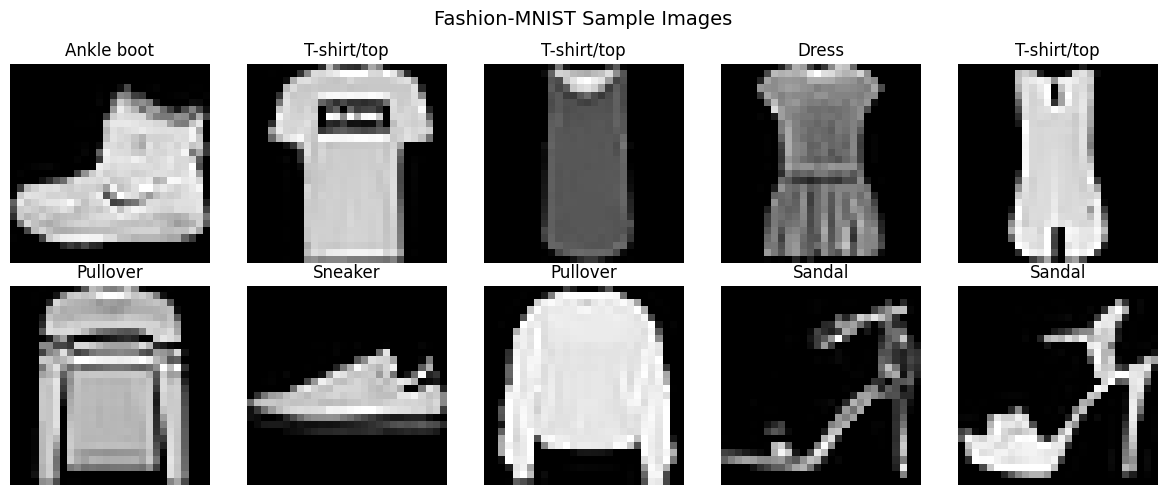

In [4]:
# Visualize sample images (provided - do not modify)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    img, label = train_dataset[i]
    ax.imshow(img.squeeze(), cmap='gray')
    ax.set_title(CLASS_NAMES[label])
    ax.axis('off')
plt.suptitle('Fashion-MNIST Sample Images', fontsize=14)
plt.tight_layout()
plt.show()

## Part 2: CNN Architecture with Feature Extraction Hooks (15 points)

Build a CNN with **forward hooks** to capture intermediate layer activations. This allows us to analyze what the network learns at each stage.

**Architecture Specification:**
```
Conv1 (1->32, kernel=3, padding=1) -> ReLU -> MaxPool(2)
Conv2 (32->64, kernel=3, padding=1) -> ReLU -> MaxPool(2)
Conv3 (64->128, kernel=3, padding=1) -> ReLU -> MaxPool(2)
Flatten -> FC1 (128*3*3 -> 256) -> ReLU -> FC2 (256 -> 10)
```

**Hints:**
- After each MaxPool(2), the spatial dimension is halved: 28 → 14 → 7 → 3
- Use `nn.Conv2d`, `nn.MaxPool2d`, `nn.Linear`
- The hook function signature is `hook(module, input, output)`

In [5]:
class CNN(nn.Module):
    """
    A simple CNN for Fashion-MNIST classification.
    Architecture:
        Conv1 (1->32) -> ReLU -> MaxPool
        Conv2 (32->64) -> ReLU -> MaxPool
        Conv3 (64->128) -> ReLU -> MaxPool
        Flatten -> FC1 (128*3*3 -> 256) -> ReLU -> FC2 (256 -> 10)
    """

    def __init__(self, num_classes=10):
        super(CNN, self).__init__()

        # TODO: Define convolutional layers
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        # TODO: Define pooling layer
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # TODO: Define fully connected layers
        # 28 -> 14 -> 7 -> 3 after 3 pools, so feature map is (128, 3, 3)
        self.fc1 = nn.Linear(128 * 3 * 3, 256)
        self.fc2 = nn.Linear(256, num_classes)

        # Storage for intermediate activations (provided)
        self.activations = {}

    def forward(self, x):
        # TODO: Implement forward pass
        # Hint: Use x.view(x.size(0), -1) to flatten
        # conv block 1
        x = self.pool(F.relu(self.conv1(x)))  # 28 -> 14

        # conv block 2
        x = self.pool(F.relu(self.conv2(x)))  # 14 -> 7

        # conv block 3
        x = self.pool(F.relu(self.conv3(x)))  # 7 -> 3
        # flatten time
        x = x.view(x.size(0), -1)
        # fc head
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x
        #pass  # Remove this line after implementing

    def register_activation_hooks(self):
        """
        Register forward hooks to capture activations at each layer.
        Returns list of hook handles for later removal.
        """
        hooks = []

        def get_activation(name):
            def hook(module, input, output):
                self.activations[name] = output.detach()
            return hook

        # TODO: Register hooks for conv1, conv2, conv3, fc1
        # Example: hooks.append(self.conv1.register_forward_hook(get_activation('conv1')))
        hooks.append(self.conv1.register_forward_hook(get_activation('conv1')))  # grab it
        hooks.append(self.conv2.register_forward_hook(get_activation('conv2')))
        hooks.append(self.conv3.register_forward_hook(get_activation('conv3')))
        hooks.append(self.fc1.register_forward_hook(get_activation('fc1')))
        return hooks

    def clear_activations(self):
        """Clear stored activations to free memory."""
        self.activations = {}

In [6]:
# Verify model architecture (run after completing CNN class)
model = CNN(num_classes=NUM_CLASSES).to(device)
print(model)

# Test forward pass
dummy_input = torch.randn(2, 1, 28, 28).to(device)
dummy_output = model(dummy_input)

# Validation assertions
assert dummy_output.shape == (2, 10), f"Expected output shape (2, 10), got {dummy_output.shape}"
print(f"\n✓ Input shape: {dummy_input.shape}")
print(f"✓ Output shape: {dummy_output.shape}")
print("✓ Model architecture verified!")

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1152, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)

✓ Input shape: torch.Size([2, 1, 28, 28])
✓ Output shape: torch.Size([2, 10])
✓ Model architecture verified!


## Part 3: Training Infrastructure (10 points)

Implement reusable training and evaluation functions.

**Hints:**
- Use `model.train()` and `model.eval()` to set training mode
- Use `optimizer.zero_grad()`, `loss.backward()`, `optimizer.step()` for training
- Use `torch.no_grad()` context for evaluation
- Compute accuracy as: `100 * correct / total`

In [7]:
def train_epoch(model, train_loader, criterion, optimizer, device):
    """
    Train for one epoch.

    Args:
        model: The CNN model
        train_loader: DataLoader for training data
        criterion: Loss function (CrossEntropyLoss)
        optimizer: Optimizer (Adam)
        device: cuda or cpu

    Returns:
        avg_loss: Average loss over all batches
        accuracy: Training accuracy (percentage)
    """
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # TODO: Implement training step
        # 1. Zero gradients
        # 2. Forward pass
        # 3. Compute loss
        # 4. Backward pass
        # 5. Update weights
        optimizer.zero_grad()    # step 1: wipe grads
        outputs = model(images)   # step 2: forward
        loss = criterion(outputs, labels)     # step 3: loss
        loss.backward()      # step 4: backward
        optimizer.step()    # step 5: update
        # TODO: Update running_loss, correct, total
        # Hint: Use outputs.max(1) to get predictions
        running_loss += loss.item()
        _, preds = outputs.max(1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()
        #pass

    return running_loss / len(train_loader), 100. * correct / total


def evaluate(model, test_loader, criterion, device):
    """
    Evaluate on test set.

    Args:
        model: The CNN model
        test_loader: DataLoader for test data
        criterion: Loss function
        device: cuda or cpu

    Returns:
        avg_loss: Average test loss
        accuracy: Test accuracy (percentage)
    """
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            # TODO: Implement evaluation step
            # 1. Forward pass
            # 2. Compute loss
            # 3. Update running_loss, correct, total
            outputs = model(images)
            loss = criterion(outputs, labels)
            running_loss += loss.item()
            _, preds = outputs.max(1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
            #pass

    return running_loss / len(test_loader), 100. * correct / total

In [8]:
def train_model(model, train_loader, test_loader, num_epochs, learning_rate, device, verbose=True):
    """
    Full training loop with loss/accuracy tracking.
    Returns training history dictionary.

    (Provided - do not modify)
    """
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {
        'train_loss': [], 'train_acc': [],
        'test_loss': [], 'test_acc': [],
        'epoch_times': []
    }

    for epoch in range(num_epochs):
        start_time = time.time()

        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        epoch_time = time.time() - start_time

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)
        history['epoch_times'].append(epoch_time)

        if verbose:
            print(f"Epoch [{epoch+1}/{num_epochs}] "
                  f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}% | "
                  f"Test Loss: {test_loss:.4f}, Test Acc: {test_acc:.2f}% | "
                  f"Time: {epoch_time:.1f}s")

    return history

## Part 4: Train Baseline CNN (Gold Standard)

First, we train a baseline CNN with **random initialization** to establish our "Gold Standard" performance.

In [9]:
# Train baseline model (provided - do not modify)
print("="*60)
print("Training Baseline CNN (Random Initialization)")
print("="*60)

baseline_model = CNN(num_classes=NUM_CLASSES).to(device)
baseline_start = time.time()
baseline_history = train_model(
    baseline_model, train_loader, test_loader,
    num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE, device=device
)
baseline_total_time = time.time() - baseline_start

print(f"\nTotal training time: {baseline_total_time:.1f}s")
print(f"Final Test Accuracy: {baseline_history['test_acc'][-1]:.2f}%")

Training Baseline CNN (Random Initialization)
Epoch [1/10] Train Loss: 0.5165, Train Acc: 81.43% | Test Loss: 0.3505, Test Acc: 87.60% | Time: 15.4s
Epoch [2/10] Train Loss: 0.3055, Train Acc: 88.79% | Test Loss: 0.3663, Test Acc: 85.87% | Time: 14.7s
Epoch [3/10] Train Loss: 0.2567, Train Acc: 90.64% | Test Loss: 0.2589, Test Acc: 90.67% | Time: 14.8s
Epoch [4/10] Train Loss: 0.2275, Train Acc: 91.65% | Test Loss: 0.2569, Test Acc: 90.40% | Time: 14.7s
Epoch [5/10] Train Loss: 0.1996, Train Acc: 92.53% | Test Loss: 0.2562, Test Acc: 90.81% | Time: 14.7s
Epoch [6/10] Train Loss: 0.1798, Train Acc: 93.43% | Test Loss: 0.2269, Test Acc: 91.65% | Time: 14.7s
Epoch [7/10] Train Loss: 0.1604, Train Acc: 94.12% | Test Loss: 0.2321, Test Acc: 91.83% | Time: 14.7s
Epoch [8/10] Train Loss: 0.1439, Train Acc: 94.56% | Test Loss: 0.2320, Test Acc: 91.83% | Time: 14.8s
Epoch [9/10] Train Loss: 0.1272, Train Acc: 95.17% | Test Loss: 0.2359, Test Acc: 92.07% | Time: 14.8s
Epoch [10/10] Train Loss: 0

## Part 5: PCA Analysis of CNN Latent Spaces (20 points)

Now we analyze **what the CNN has learned** by extracting activations from each layer and applying PCA to visualize the representation structure.

**Tasks:**
1. Implement `extract_activations()` to get layer outputs using hooks
2. Implement `visualize_pca_latent_space()` to create PCA visualizations

**Hints:**
- For conv layers with shape (B, C, H, W), use global average pooling: `act.mean(dim=(2, 3))`
- Use `StandardScaler` before PCA
- Plot 2D scatter colored by class labels

In [10]:
def extract_activations(model, data_loader, device, num_samples=2000):
    """
    Extract activations from all hooked layers for a subset of data.

    Args:
        model: Trained CNN with activation hooks
        data_loader: DataLoader to extract activations from
        device: cuda or cpu
        num_samples: Maximum number of samples to process

    Returns:
        all_activations: dict of {layer_name: numpy array of shape (num_samples, features)}
        all_labels: numpy array of labels
    """
    model.eval()
    hooks = model.register_activation_hooks()

    all_activations = {name: [] for name in ['conv1', 'conv2', 'conv3', 'fc1']}
    all_labels = []
    samples_collected = 0

    with torch.no_grad():
        for images, labels in data_loader:
            if samples_collected >= num_samples:
                break

            # TODO: Move images to device and run forward pass
            # The forward pass will trigger the hooks and populate model.activations
            images = images.to(device)
            _ = model(images)  # forward triggers hooks, nice

            remaining = num_samples - samples_collected
            batch_take = min(remaining, labels.size(0))
            for name in all_activations.keys():
                # TODO: Get activation from model.activations[name]
                # For conv layers (4D tensor), apply global average pooling
                # Hint: if len(act.shape) == 4: act = act.mean(dim=(2, 3))
                act = model.activations[name]  # tensor
                if len(act.shape) == 4:
                    act = act.mean(dim=(2, 3))  # (B, C)

                # take only what we still need
                act = act[:batch_take]
                all_activations[name].append(act.cpu())
                #pass

            # TODO: Append labels and update samples_collected
            all_labels.append(labels[:batch_take].cpu())
            samples_collected += batch_take
            model.clear_activations()

    # Remove hooks
    for hook in hooks:
        hook.remove()

    # TODO: Concatenate all batches and convert to numpy
    # Slice to exactly num_samples
    for name in all_activations.keys():
        all_activations[name] = torch.cat(all_activations[name], dim=0)[:num_samples].numpy()

    all_labels = torch.cat(all_labels, dim=0)[:num_samples].numpy()
    return all_activations, all_labels

In [11]:
# Extract activations from trained baseline model
print("Extracting activations from trained CNN...")
activations, labels = extract_activations(baseline_model, test_loader, device, num_samples=2000)

# Validation
print("\nActivation shapes per layer:")
for name, act in activations.items():
    print(f"  {name}: {act.shape}")
    assert len(act) == 2000, f"Expected 2000 samples, got {len(act)}"

print("\n✓ Activation extraction verified!")

Extracting activations from trained CNN...

Activation shapes per layer:
  conv1: (2000, 32)
  conv2: (2000, 64)
  conv3: (2000, 128)
  fc1: (2000, 256)

✓ Activation extraction verified!


In [12]:
def visualize_pca_latent_space(activations, labels, layer_name, class_names):
    """
    Apply PCA to layer activations and create 2D visualization.

    Args:
        activations: numpy array of shape (num_samples, features)
        labels: numpy array of class labels
        layer_name: Name of the layer (for plot title)
        class_names: List of class names for legend

    Returns:
        pca: Fitted PCA object
        n_components_95: Number of components for 95% variance
    """
    # TODO: Step 1 - Standardize features using StandardScaler
    scaler = StandardScaler()
    X = scaler.fit_transform(activations)

    # TODO: Step 2 - Apply PCA with n_components = min(50, num_features)
    n_pca = min(50, X.shape[1])
    pca = PCA(n_components=n_pca, random_state=42)
    X_pca = pca.fit_transform(X)

    explained = pca.explained_variance_ratio_
    cum_explained = np.cumsum(explained) #lolllll

    # TODO: Find number of components for 95% variance
    n_components_95 = int(np.argmax(cum_explained >= 0.95) + 1)  # +1 because index

    # Create visualization (provided structure)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    # TODO: Left plot - 2D scatter of PC1 vs PC2, colored by labels
    for c in range(len(class_names)):
        mask = (labels == c)
        axes[0].scatter(
            X_pca[mask, 0], X_pca[mask, 1],
            s=12, alpha=0.6, label=class_names[c])
    axes[0].set_xlabel('PC1')
    axes[0].set_ylabel('PC2')
    axes[0].set_title(
        f"{layer_name} PCA (PC1={explained[0]*100:.1f}%, PC2={explained[1]*100:.1f}%)"
    )
    axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
    axes[0].grid(True, alpha=0.25)
    # TODO: Right plot - Cumulative explained variance + 95% threshold line
    axes[1].plot(range(1, len(cum_explained) + 1), cum_explained, linewidth=2)
    axes[1].axhline(0.95, linestyle='--', linewidth=2)
    axes[1].axvline(n_components_95, linestyle='--', linewidth=2)
    axes[1].set_xlabel('Number of Components')
    axes[1].set_ylabel('Cumulative Explained Variance')
    axes[1].set_title(f'Cumulative Variance (95% at {n_components_95} comps)')
    axes[1].grid(True, alpha=0.25)

    plt.tight_layout()
    plt.show()
# used ai help as i of course not remember or know or rote learned plotting syntax
    return pca, n_components_95


Analyzing Layer: conv1


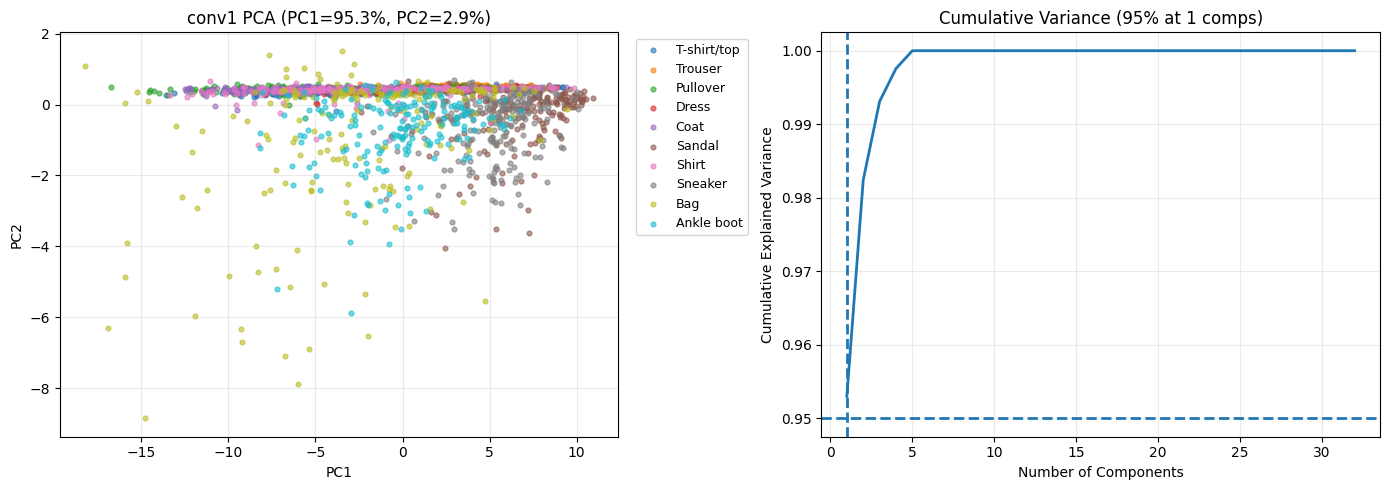

Components needed for 95% variance: 1

Analyzing Layer: conv2


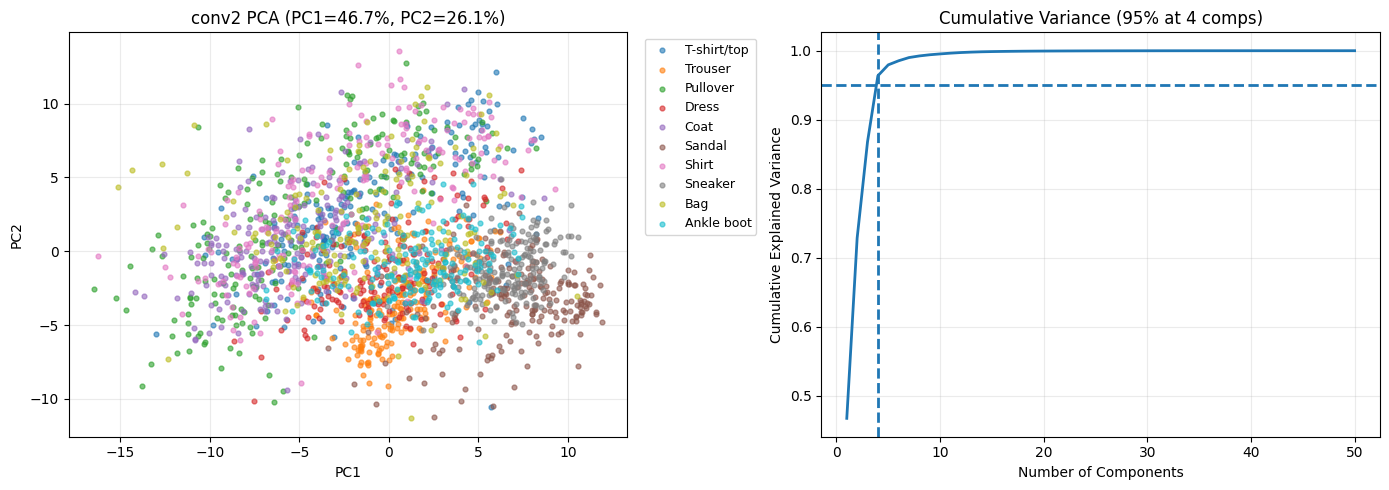

Components needed for 95% variance: 4

Analyzing Layer: conv3


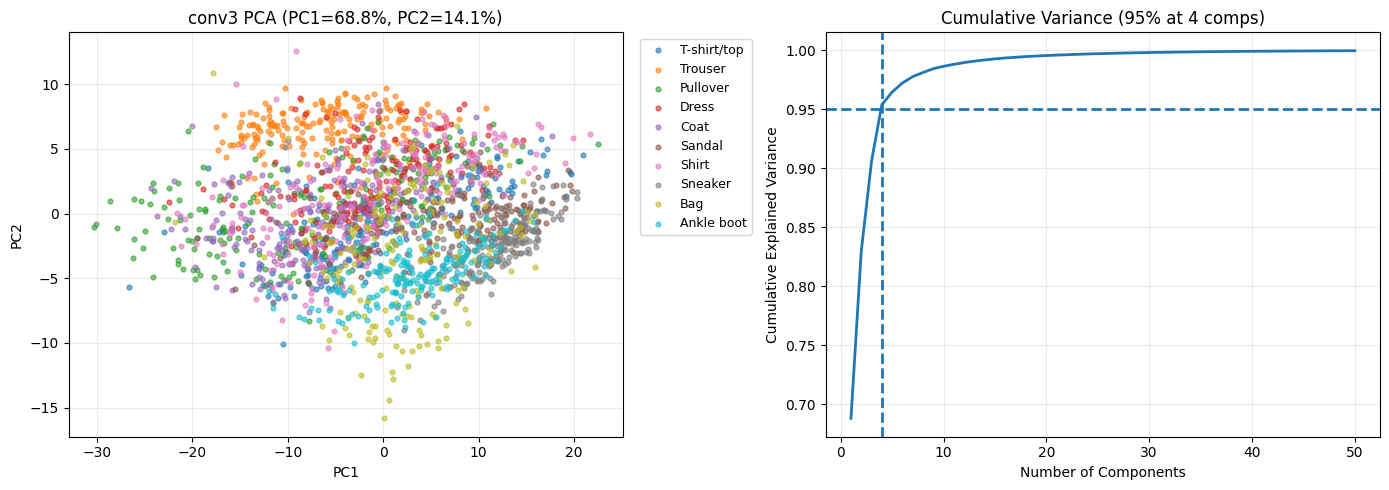

Components needed for 95% variance: 4

Analyzing Layer: fc1


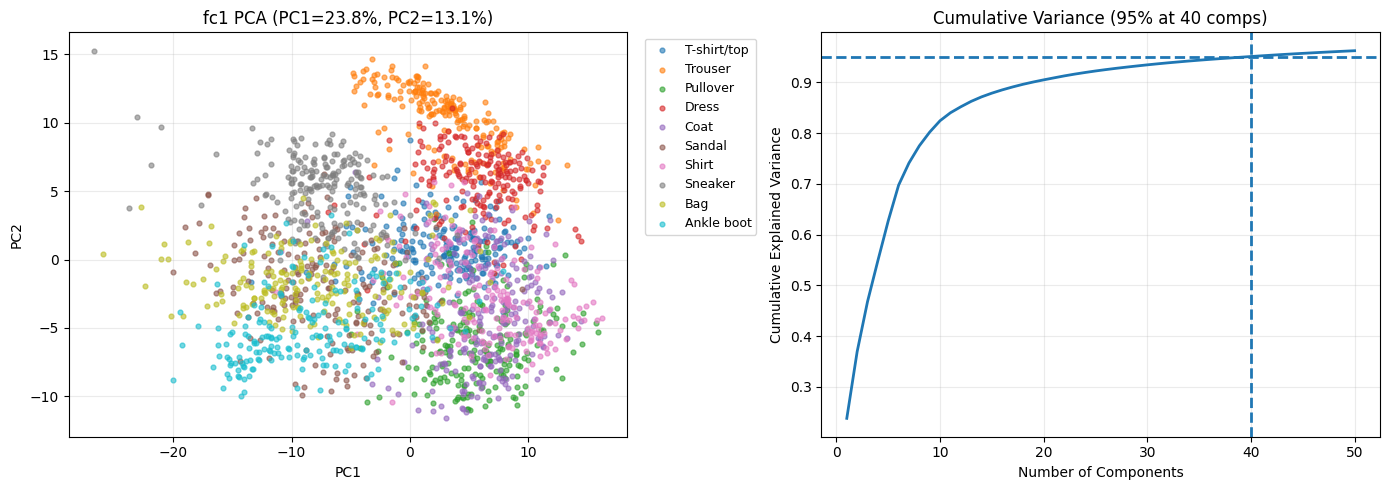

Components needed for 95% variance: 40


In [13]:
# Visualize PCA for each layer
intrinsic_dims = {}

for layer_name in ['conv1', 'conv2', 'conv3', 'fc1']:
    print(f"\n{'='*50}")
    print(f"Analyzing Layer: {layer_name}")
    print(f"{'='*50}")

    pca, n_components = visualize_pca_latent_space(
        activations[layer_name], labels, layer_name, CLASS_NAMES
    )
    intrinsic_dims[layer_name] = n_components
    print(f"Components needed for 95% variance: {n_components}")


INTRINSIC DIMENSIONALITY SUMMARY


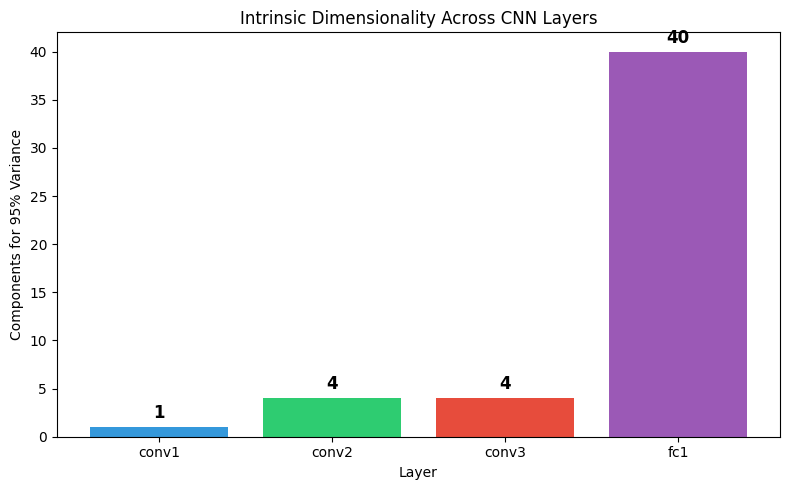

In [14]:
# Summary: Intrinsic dimensionality across layers (provided)
print("\n" + "="*50)
print("INTRINSIC DIMENSIONALITY SUMMARY")
print("="*50)

layers = list(intrinsic_dims.keys())
dims = list(intrinsic_dims.values())

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(layers, dims, color=['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'])
ax.set_xlabel('Layer')
ax.set_ylabel('Components for 95% Variance')
ax.set_title('Intrinsic Dimensionality Across CNN Layers')

# Add value labels on bars
for bar, dim in zip(bars, dims):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            str(dim), ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 📝 Analysis Question 5.1 (5 points)

Based on the intrinsic dimensionality analysis:

1. How does the intrinsic dimensionality change as we go deeper in the network?
2. What does this suggest about how the CNN processes information?
3. Which layer has the most class-separable representations (based on the PCA scatter plots)?

**Your Answer:** (Write 3-5 sentences)



*[Double-click to edit this cell and write your answer here]*

Answer 1: the intrinsic dimensionality is very low in the early layers (conv1 needs only 1 component for 95 percent variance), stays small in the mid layers (conv2 and conv3 need 4), and then jumps a lot at the fully connected layer (fc1 needs 40)

Answer 2: this suggests the CNN starts by extracting a small set of generic, shared visual patterns (simple edges and local textures), then gradually builds richer feature combinations, and finally expands into a much more detailed feature space to separate classses

Answer 3: fc1 shows the most class-separable representations in the PCA scatter plots, because the clusters look the most organized and distinct there compared to the heavy overlap in conv1 and the still-mixed structure in conv2/conv3




## Part 6: PCA-Initialized Convolutional Filters (20 points)

Now we explore whether we can use **PCA eigenvectors** to initialize the first convolutional layer. The idea is that PCA captures the principal directions of variation in image patches, which might provide a better starting point than random initialization.

**Tasks:**
1. Implement `extract_patches()` to extract image patches
2. Implement `compute_pca_filters()` to compute PCA eigenvectors as filters
3. Implement `create_pca_initialized_model()` to initialize CNN with PCA filters

**Key Insight:**
- Our conv1 uses 3×3 kernels and needs 32 filters
- But 3×3 patches only have 9 features, so we can only get 9 PCA components
- Solution: Extract larger 7×7 patches (49 features ≥ 32), then crop to central 3×3

In [17]:
def extract_patches(images, patch_size=3, stride=1, max_patches=50000):
    """
    Extract patches from images for PCA analysis.

    Args:
        images: Tensor of shape (N, 1, H, W)
        patch_size: Size of square patches to extract
        stride: Stride between patches
        max_patches: Maximum number of patches to return

    Returns:
        patches: Array of shape (num_patches, patch_size * patch_size)
    """
    patches = []
    patch_dim = patch_size * patch_size
    for img in images:
        img = img.squeeze().numpy()  # (H, W)
        h, w = img.shape

        # TODO: Extract patches using nested loops
        for i in range(0, h - patch_size + 1, stride):
            for j in range(0, w - patch_size + 1, stride):
                patch = img[i:i+patch_size, j:j+patch_size].reshape(-1)  # (patch_dim,)
                patches.append(patch)

                # stop early if we got enough, simple
                if len(patches) >= max_patches:
                    return np.array(patches, dtype=np.float32).reshape(-1, patch_dim)
       # pass
    return np.array(patches, dtype=np.float32).reshape(-1, patch_dim)
    #return np.array(patches)

In [18]:
# Extract patches from training images (unnormalized for PCA)
print("Extracting image patches for PCA...")

# Load raw images without normalization
raw_transform = transforms.ToTensor()
raw_train_dataset = torchvision.datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=raw_transform
)

# Get subset of images
num_images_for_pca = 5000
raw_images = torch.stack([raw_train_dataset[i][0] for i in range(num_images_for_pca)])

# Extract 7x7 patches to get enough features for 32+ PCA components
PATCH_SIZE_FOR_PCA = 7

patches = extract_patches(raw_images, patch_size=PATCH_SIZE_FOR_PCA, stride=3, max_patches=100000)

# Validation
assert patches.shape[1] == 49, f"Expected patch size 49 (7x7), got {patches.shape[1]}"
print(f"Extracted {len(patches)} patches of shape {patches[0].shape} ({PATCH_SIZE_FOR_PCA}x{PATCH_SIZE_FOR_PCA})")

Extracting image patches for PCA...
Extracted 100000 patches of shape (49,) (7x7)


In [19]:
def compute_pca_filters(patches, num_filters=32, output_kernel_size=3):
    """
    Compute PCA eigenvectors from patches to use as convolutional filters.

    Since conv1 uses 3x3 kernels but we need 32 filters, we extract larger patches
    (7x7=49 features) to get enough PCA components, then crop to the central 3x3.

    Args:
        patches: Array of shape (num_patches, patch_dim) where patch_dim >= num_filters
        num_filters: Number of eigenvectors/filters to compute
        output_kernel_size: Size of the output conv kernel (default 3 for 3x3)

    Returns:
        filters: Tensor of shape (num_filters, 1, output_kernel_size, output_kernel_size)
        pca: Fitted PCA object
    """
    patch_dim = patches.shape[1]
    max_components = min(num_filters, patch_dim, len(patches))

    # infer full patch side length (e.g., 49 -> 7)
    full_side = int(np.sqrt(patch_dim))
    assert full_side * full_side == patch_dim, "patch_dim must be a perfect square"

    # TODO: Step 1 - Center the patches (subtract mean)
    patch_mean = patches.mean(axis=0, keepdims=True)
    patches_centered = patches - patch_mean

    # TODO: Step 2 - Fit PCA with max_components
    pca = PCA(n_components=max_components, random_state=42)
    pca.fit(patches_centered)

    # TODO: Step 3 - Get eigenvectors (principal components)
    # shape: (max_components, patch_dim)
    eigvecs = pca.components_
    # TODO: Step 4 - Reshape to full patch size
    eig_imgs = eigvecs.reshape(max_components, full_side, full_side)
    # TODO: Step 5 - Crop to central output_kernel_size x output_kernel_size region
    k = output_kernel_size
    start = (full_side -k)// 2
    end = start + k
    cropped = eig_imgs[:, start:end, start:end]  # (max_components, k, k)
    # If we got < num_filters (shouldn't here), pad zeros just in case
    if max_components < num_filters:
        pad_amt = num_filters - max_components
        cropped = np.concatenate([cropped, np.zeros((pad_amt, k, k), dtype=cropped.dtype)], axis=0)
    # TODO: Step 6 - Reshape to conv filter format: (num_filters, 1, H, W)
    filt = cropped[:num_filters].reshape(num_filters, 1, k, k)
    # TODO: Step 7 - Normalize filters to Kaiming scale
    # Aim: similar scale as kaiming_normal_ for Conv2d
    # fan_in = 1 * k * k
    fan_in = 1 * k * k
    target_std = np.sqrt(2.0 / fan_in)
    cur_std = filt.std()
    if cur_std > 1e-8:
        filt = filt * (target_std / cur_std)

    # TODO: Step 8 - Convert to torch tensor
    filters = torch.tensor(filt, dtype=torch.float32)

    return filters, pca

In [20]:
# Compute PCA filters
print("Computing PCA eigenvectors as filters...")
pca_filters, patch_pca = compute_pca_filters(patches, num_filters=32)

# Validation
assert pca_filters.shape == (32, 1, 3, 3), f"Expected shape (32, 1, 3, 3), got {pca_filters.shape}"
print(f"✓ PCA filters shape: {pca_filters.shape}")
print(f"✓ Explained variance by 32 components: {patch_pca.explained_variance_ratio_.sum()*100:.1f}%")

Computing PCA eigenvectors as filters...
✓ PCA filters shape: torch.Size([32, 1, 3, 3])
✓ Explained variance by 32 components: 98.9%


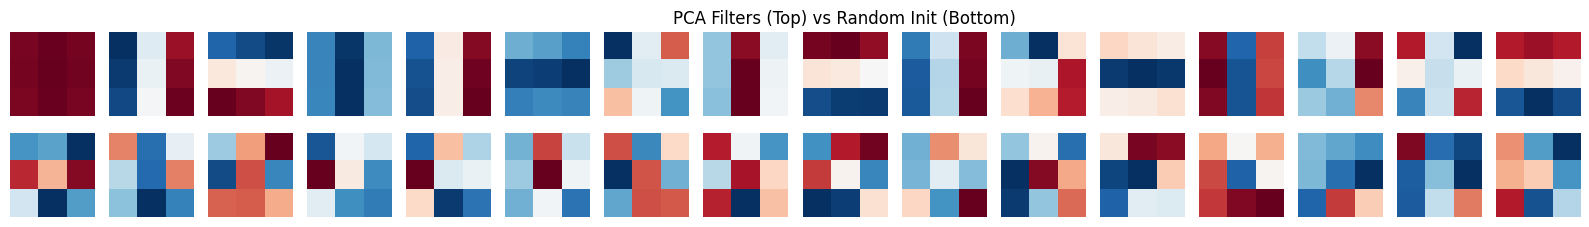


Observation: PCA filters often capture edge detectors and gradient patterns,
while random filters are unstructured noise.


In [21]:
# Visualize PCA filters vs random filters (provided)
fig, axes = plt.subplots(2, 16, figsize=(16, 2.5))

# Row 1: PCA filters (first 16)
for i, ax in enumerate(axes[0]):
    filt = pca_filters[i, 0].cpu().numpy()
    vmax = np.abs(filt).max()
    ax.imshow(filt, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.axis('off')
    if i == 0:
        ax.set_ylabel('PCA', fontsize=10)

# Row 2: Random filters (from a fresh model)
random_model = CNN()
random_filters = random_model.conv1.weight.data
for i, ax in enumerate(axes[1]):
    filt = random_filters[i, 0].cpu().numpy()
    vmax = np.abs(filt).max()
    ax.imshow(filt, cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.axis('off')
    if i == 0:
        ax.set_ylabel('Random', fontsize=10)

axes[0, 8].set_title('PCA Filters (Top) vs Random Init (Bottom)', fontsize=12)
plt.tight_layout()
plt.show()

print("\nObservation: PCA filters often capture edge detectors and gradient patterns,")
print("while random filters are unstructured noise.")

In [22]:
def create_pca_initialized_model(pca_filters, num_classes=10):
    """
    Create a CNN with the first conv layer initialized using PCA filters.

    Args:
        pca_filters: Tensor of shape (32, 1, 3, 3)
        num_classes: Number of output classes

    Returns:
        model: CNN with PCA-initialized conv1
    """
    model = CNN(num_classes=num_classes)

    # TODO: Initialize conv1 with PCA filters
    # Use torch.no_grad() context and model.conv1.weight.copy_()
    # Also zero out the bias: model.conv1.bias.zero_()
    with torch.no_grad():
        model.conv1.weight.copy_(pca_filters)  #slap them in
        if model.conv1.bias is not None:
            model.conv1.bias.zero_()
    return model

In [23]:
# Train PCA-initialized model
print("="*60)
print("Training PCA-Initialized CNN")
print("="*60)

pca_model = create_pca_initialized_model(pca_filters, num_classes=NUM_CLASSES).to(device)
pca_start = time.time()
pca_history = train_model(
    pca_model, train_loader, test_loader,
    num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE, device=device
)
pca_total_time = time.time() - pca_start

print(f"\nTotal training time: {pca_total_time:.1f}s")
print(f"Final Test Accuracy: {pca_history['test_acc'][-1]:.2f}%")

Training PCA-Initialized CNN
Epoch [1/10] Train Loss: 0.4374, Train Acc: 84.10% | Test Loss: 0.3273, Test Acc: 88.53% | Time: 15.4s
Epoch [2/10] Train Loss: 0.2685, Train Acc: 90.09% | Test Loss: 0.2886, Test Acc: 89.64% | Time: 15.1s
Epoch [3/10] Train Loss: 0.2275, Train Acc: 91.68% | Test Loss: 0.2534, Test Acc: 90.69% | Time: 15.0s
Epoch [4/10] Train Loss: 0.1986, Train Acc: 92.67% | Test Loss: 0.2417, Test Acc: 91.48% | Time: 15.1s
Epoch [5/10] Train Loss: 0.1735, Train Acc: 93.53% | Test Loss: 0.2356, Test Acc: 91.67% | Time: 14.9s
Epoch [6/10] Train Loss: 0.1528, Train Acc: 94.31% | Test Loss: 0.2370, Test Acc: 91.63% | Time: 14.9s
Epoch [7/10] Train Loss: 0.1312, Train Acc: 95.05% | Test Loss: 0.2493, Test Acc: 91.51% | Time: 14.9s
Epoch [8/10] Train Loss: 0.1145, Train Acc: 95.68% | Test Loss: 0.2367, Test Acc: 92.18% | Time: 15.0s
Epoch [9/10] Train Loss: 0.0970, Train Acc: 96.34% | Test Loss: 0.3081, Test Acc: 91.51% | Time: 14.8s
Epoch [10/10] Train Loss: 0.0868, Train Acc:

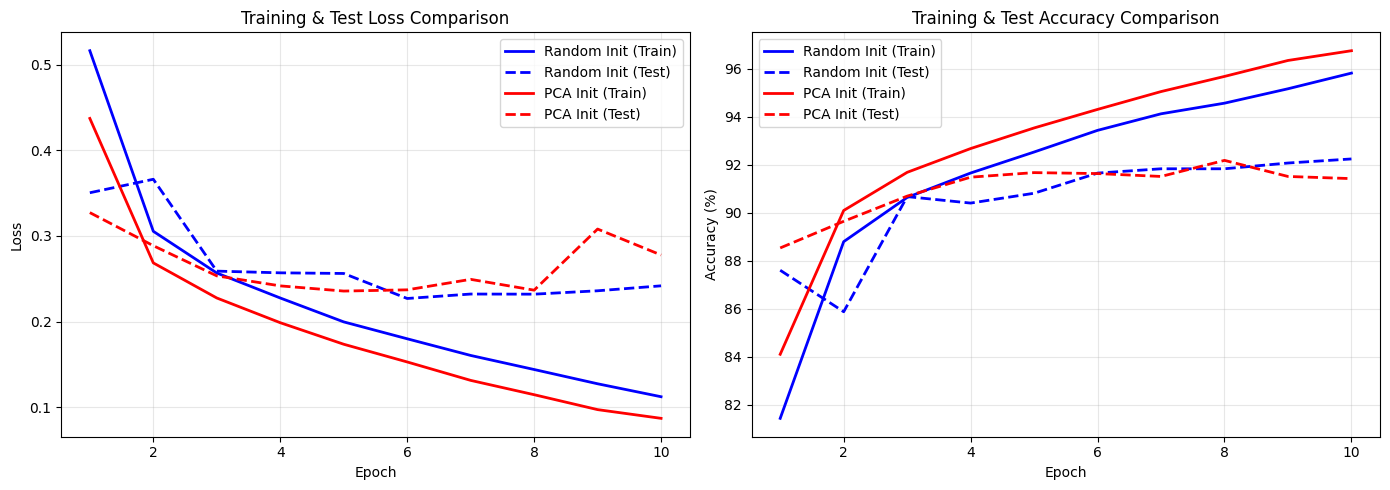


INITIALIZATION COMPARISON SUMMARY
Metric                         Random Init     PCA Init       
------------------------------------------------------------
Final Test Accuracy (%)        92.24           91.42          
Epoch 1 Test Accuracy (%)      87.60           88.53          
Total Training Time (s)        147.8           149.9          


In [24]:
# Compare training curves: Random Init vs PCA Init (provided)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = range(1, NUM_EPOCHS + 1)

# Loss comparison
axes[0].plot(epochs, baseline_history['train_loss'], 'b-', label='Random Init (Train)', linewidth=2)
axes[0].plot(epochs, baseline_history['test_loss'], 'b--', label='Random Init (Test)', linewidth=2)
axes[0].plot(epochs, pca_history['train_loss'], 'r-', label='PCA Init (Train)', linewidth=2)
axes[0].plot(epochs, pca_history['test_loss'], 'r--', label='PCA Init (Test)', linewidth=2)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Test Loss Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy comparison
axes[1].plot(epochs, baseline_history['train_acc'], 'b-', label='Random Init (Train)', linewidth=2)
axes[1].plot(epochs, baseline_history['test_acc'], 'b--', label='Random Init (Test)', linewidth=2)
axes[1].plot(epochs, pca_history['train_acc'], 'r-', label='PCA Init (Train)', linewidth=2)
axes[1].plot(epochs, pca_history['test_acc'], 'r--', label='PCA Init (Test)', linewidth=2)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training & Test Accuracy Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary statistics
print("\n" + "="*60)
print("INITIALIZATION COMPARISON SUMMARY")
print("="*60)
print(f"{'Metric':<30} {'Random Init':<15} {'PCA Init':<15}")
print("-"*60)
print(f"{'Final Test Accuracy (%)':<30} {baseline_history['test_acc'][-1]:<15.2f} {pca_history['test_acc'][-1]:<15.2f}")
print(f"{'Epoch 1 Test Accuracy (%)':<30} {baseline_history['test_acc'][0]:<15.2f} {pca_history['test_acc'][0]:<15.2f}")
print(f"{'Total Training Time (s)':<30} {baseline_total_time:<15.1f} {pca_total_time:<15.1f}")

### 📝 Analysis Question 6.1 (5 points)

Based on the PCA initialization experiment:

1. Does PCA initialization help in the **early epochs**? By how much?
2. Does PCA initialization improve **final accuracy**? Why or why not?
3. When would PCA initialization be most valuable in practice?

**Your Answer:** (Write 3-5 sentences)

*[Double-click to edit this cell and write your answer here]*

Answer 1: Yes, PCA initialization helps in the early epochs: in epoch 1 my test accuracy goes from 87.60% (random init) to 88.53% (PCA init), an improvement of about 0.93 percentage points, which matches the accuracy plot showing PCA starting slightly higher

Answer 2: PCA initialization does not improve final accuracy here: 92.24% (random init) vs 91.42% (PCA init), because after a few epochs both models quickly learn similar low level edge and gradient like filters anyway, so the “better starting point” advantage mostly disapears (and can even slightly hurt if it biases learning in a direction that is not optimal for the full task). The filter visualisation also supports why it helps early: PCA filters already look structured (edge/gradient patterns) while random filters look noisy, so the network starts with more meaningful feature detectors

Answer 3: PCA initialization is most valuable when you have very limited training time/epochs, limited data, or tight compute constraints, where faster early convergence matters more than squeezing the absolute best final accuracy .


## Part 7: Ablation Lab — PCA Component Budget (20 points)

The core ablation experiment: **How many PCA components are needed in the input before CNN performance saturates?**

We will:
1. Apply PCA to the flattened input images
2. Reconstruct images using k = {10, 50, 100, 200, 500, 784} components
3. Train a CNN on each reconstructed dataset
4. Analyze accuracy vs. retained variance

In [25]:
def apply_pca_to_images(train_images, test_images, n_components):
    """
    Apply PCA dimensionality reduction to images.

    Args:
        train_images: Array of shape (N_train, 784) - flattened images
        test_images: Array of shape (N_test, 784) - flattened images
        n_components: Number of PCA components to keep

    Returns:
        train_reconstructed: Reconstructed training images (N_train, 784)
        test_reconstructed: Reconstructed test images (N_test, 784)
        explained_var: Total explained variance ratio
    """
    # TODO: Step 1 - Create PCA object with n_components
    pca = PCA(n_components=n_components, random_state=42)
    # TODO: Step 2 - Fit on training data and transform both sets
    train_low = pca.fit_transform(train_images)
    test_low = pca.transform(test_images)
    # TODO: Step 3 - Reconstruct images using inverse_transform
    train_reconstructed = pca.inverse_transform(train_low)
    test_reconstructed = pca.inverse_transform(test_low)
    # TODO: Step 4 - Get total explained variance
    explained_var = float(pca.explained_variance_ratio_.sum())
    return train_reconstructed, test_reconstructed, explained_var

    #pass  # Remove this line after implementing acha bhai

In [26]:
# Prepare flattened images for PCA (provided)
print("Preparing data for PCA ablation study...")

# Load raw (unnormalized) data for PCA
raw_train = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True)
raw_test = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True)

# Convert to numpy arrays and flatten
train_images_flat = raw_train.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
test_images_flat = raw_test.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
train_labels_np = raw_train.targets.numpy()
test_labels_np = raw_test.targets.numpy()

print(f"Training images shape: {train_images_flat.shape}")
print(f"Test images shape: {test_images_flat.shape}")

Preparing data for PCA ablation study...
Training images shape: (60000, 784)
Test images shape: (10000, 784)


In [27]:
# Run ablation experiment (this will take ~15-20 minutes)
COMPONENT_BUDGETS = [10, 50, 100, 200, 500, 784]  # 784 = full dimensionality

ablation_results = []

for n_components in COMPONENT_BUDGETS:
    print(f"\n{'='*60}")
    print(f"Training with {n_components} PCA components")
    print(f"{'='*60}")

    # Apply PCA (or skip for full dimensionality)
    if n_components < 784:
        train_recon, test_recon, explained_var = apply_pca_to_images(
            train_images_flat, test_images_flat, n_components
        )
        print(f"Explained variance: {explained_var*100:.2f}%")
    else:
        train_recon = train_images_flat
        test_recon = test_images_flat
        explained_var = 1.0
        print("Using full dimensionality (no PCA)")

    # Reshape to image format and normalize
    train_recon_tensor = torch.tensor(train_recon.reshape(-1, 1, 28, 28), dtype=torch.float32)
    test_recon_tensor = torch.tensor(test_recon.reshape(-1, 1, 28, 28), dtype=torch.float32)

    # Normalize using Fashion-MNIST statistics
    train_recon_tensor = (train_recon_tensor - 0.2860) / 0.3530
    test_recon_tensor = (test_recon_tensor - 0.2860) / 0.3530

    # Create data loaders
    train_labels_tensor = torch.tensor(train_labels_np, dtype=torch.long)
    test_labels_tensor = torch.tensor(test_labels_np, dtype=torch.long)

    pca_train_dataset = TensorDataset(train_recon_tensor, train_labels_tensor)
    pca_test_dataset = TensorDataset(test_recon_tensor, test_labels_tensor)

    pca_train_loader = DataLoader(pca_train_dataset, batch_size=BATCH_SIZE, shuffle=True)
    pca_test_loader = DataLoader(pca_test_dataset, batch_size=BATCH_SIZE, shuffle=False)

    # Train model
    model = CNN(num_classes=NUM_CLASSES).to(device)
    start_time = time.time()
    history = train_model(
        model, pca_train_loader, pca_test_loader,
        num_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE, device=device,
        verbose=False
    )
    training_time = time.time() - start_time

    final_acc = history['test_acc'][-1]
    print(f"Final Test Accuracy: {final_acc:.2f}%")
    print(f"Training Time: {training_time:.1f}s")

    ablation_results.append({
        'n_components': n_components,
        'explained_variance': explained_var,
        'test_accuracy': final_acc,
        'training_time': training_time,
        'history': history
    })


Training with 10 PCA components
Explained variance: 71.99%
Final Test Accuracy: 83.26%
Training Time: 18.3s

Training with 50 PCA components
Explained variance: 86.27%
Final Test Accuracy: 89.70%
Training Time: 18.3s

Training with 100 PCA components
Explained variance: 91.23%
Final Test Accuracy: 90.74%
Training Time: 18.2s

Training with 200 PCA components
Explained variance: 95.36%
Final Test Accuracy: 91.28%
Training Time: 18.3s

Training with 500 PCA components
Explained variance: 99.26%
Final Test Accuracy: 91.92%
Training Time: 18.2s

Training with 784 PCA components
Using full dimensionality (no PCA)
Final Test Accuracy: 92.27%
Training Time: 18.3s


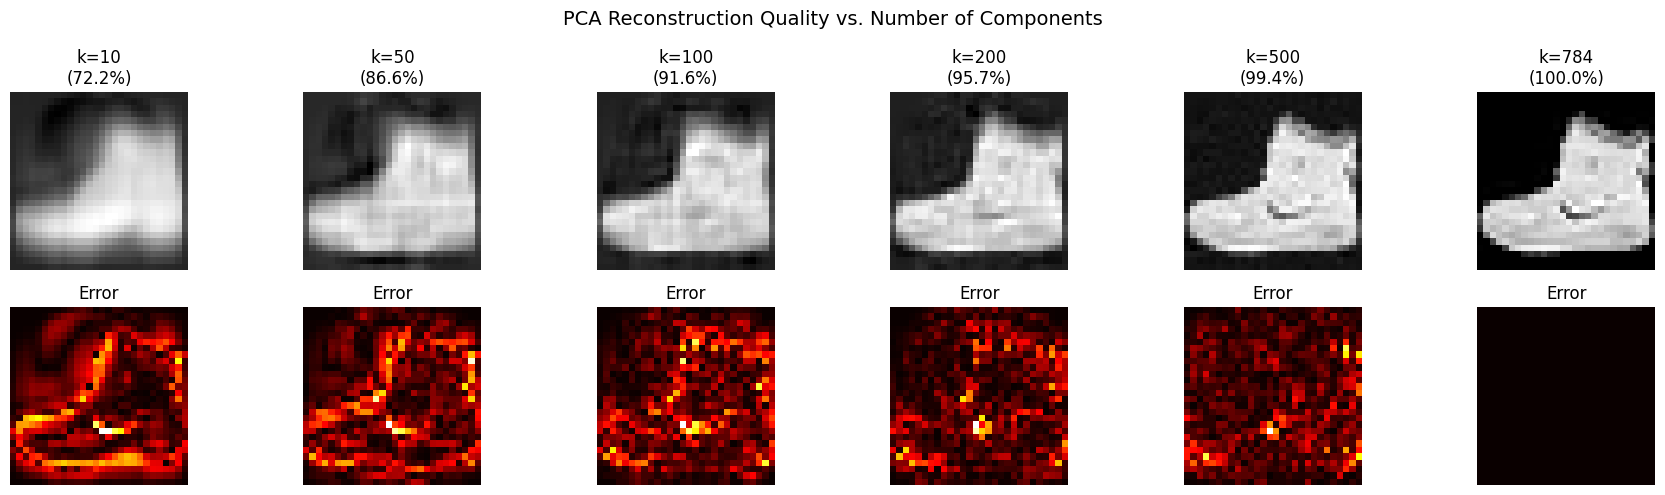

In [28]:
# Visualize reconstructed images at different component levels (provided)
sample_idx = 0
sample_image = train_images_flat[sample_idx]

fig, axes = plt.subplots(2, len(COMPONENT_BUDGETS), figsize=(18, 5))

for i, n_components in enumerate(COMPONENT_BUDGETS):
    if n_components < 784:
        pca = PCA(n_components=n_components)
        pca.fit(train_images_flat[:5000])
        reduced = pca.transform(sample_image.reshape(1, -1))
        reconstructed = pca.inverse_transform(reduced).reshape(28, 28)
        var = pca.explained_variance_ratio_.sum()
    else:
        reconstructed = sample_image.reshape(28, 28)
        var = 1.0

    axes[0, i].imshow(reconstructed, cmap='gray')
    axes[0, i].set_title(f'k={n_components}\n({var*100:.1f}%)')
    axes[0, i].axis('off')

    # Show difference from original
    diff = np.abs(sample_image.reshape(28, 28) - reconstructed)
    axes[1, i].imshow(diff, cmap='hot')
    axes[1, i].set_title(f'Error')
    axes[1, i].axis('off')

axes[0, 0].set_ylabel('Reconstruction', fontsize=10)
axes[1, 0].set_ylabel('Abs. Error', fontsize=10)
plt.suptitle('PCA Reconstruction Quality vs. Number of Components', fontsize=14)
plt.tight_layout()
plt.show()

In [29]:
# Ablation Results Summary (provided)
print("\n" + "="*70)
print("ABLATION STUDY RESULTS: PCA COMPONENT BUDGET")
print("="*70)
print(f"{'Components':<12} {'Var Explained':<16} {'Test Acc (%)':<14} {'Time (s)':<10}")
print("-"*70)

for result in ablation_results:
    print(f"{result['n_components']:<12} {result['explained_variance']*100:<16.2f} "
          f"{result['test_accuracy']:<14.2f} {result['training_time']:<10.1f}")


ABLATION STUDY RESULTS: PCA COMPONENT BUDGET
Components   Var Explained    Test Acc (%)   Time (s)  
----------------------------------------------------------------------
10           71.99            83.26          18.3      
50           86.27            89.70          18.3      
100          91.23            90.74          18.2      
200          95.36            91.28          18.3      
500          99.26            91.92          18.2      
784          100.00           92.27          18.3      


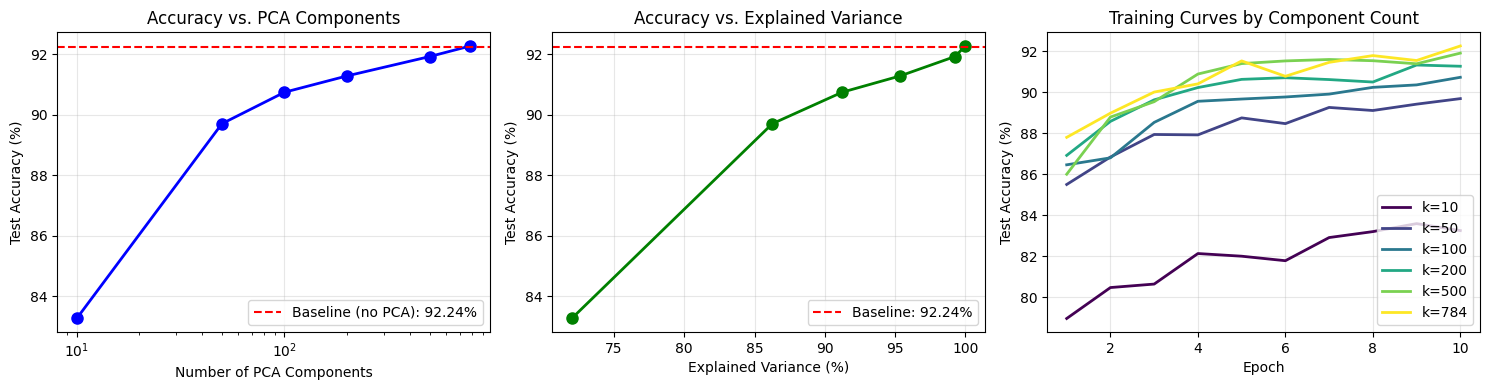

In [30]:
# Visualization: Ablation Results (provided)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

components = [r['n_components'] for r in ablation_results]
accuracies = [r['test_accuracy'] for r in ablation_results]
variances = [r['explained_variance'] * 100 for r in ablation_results]
times = [r['training_time'] for r in ablation_results]

# Plot 1: Accuracy vs Components
axes[0].plot(components, accuracies, 'bo-', linewidth=2, markersize=8)
axes[0].axhline(y=baseline_history['test_acc'][-1], color='r', linestyle='--',
                label=f'Baseline (no PCA): {baseline_history["test_acc"][-1]:.2f}%')
axes[0].set_xlabel('Number of PCA Components')
axes[0].set_ylabel('Test Accuracy (%)')
axes[0].set_title('Accuracy vs. PCA Components')
axes[0].set_xscale('log')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Accuracy vs Explained Variance
axes[1].plot(variances, accuracies, 'go-', linewidth=2, markersize=8)
axes[1].axhline(y=baseline_history['test_acc'][-1], color='r', linestyle='--',
                label=f'Baseline: {baseline_history["test_acc"][-1]:.2f}%')
axes[1].set_xlabel('Explained Variance (%)')
axes[1].set_ylabel('Test Accuracy (%)')
axes[1].set_title('Accuracy vs. Explained Variance')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Training curves comparison
colors = plt.cm.viridis(np.linspace(0, 1, len(ablation_results)))
for result, color in zip(ablation_results, colors):
    axes[2].plot(range(1, NUM_EPOCHS+1), result['history']['test_acc'],
                 color=color, label=f"k={result['n_components']}", linewidth=2)
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Test Accuracy (%)')
axes[2].set_title('Training Curves by Component Count')
axes[2].legend(loc='lower right')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
# Find the "knee" - diminishing returns analysis (provided)
accuracy_gains = np.diff(accuracies)
component_increases = np.diff(components)
efficiency = accuracy_gains / component_increases

print("\n" + "="*60)
print("DIMINISHING RETURNS ANALYSIS")
print("="*60)
print(f"{'Transition':<20} {'Acc Gain (%)':<15} {'Components Added':<18} {'Efficiency':<12}")
print("-"*60)

for i in range(len(accuracy_gains)):
    transition = f"{components[i]} → {components[i+1]}"
    print(f"{transition:<20} {accuracy_gains[i]:<15.2f} {component_increases[i]:<18} {efficiency[i]:<12.4f}")

# Find optimal point (highest efficiency)
optimal_idx = np.argmax(efficiency)
print(f"\n🎯 Recommended: Use {components[optimal_idx+1]} components")
print(f"   Achieves {accuracies[optimal_idx+1]:.2f}% accuracy with {variances[optimal_idx+1]:.1f}% variance retained")


DIMINISHING RETURNS ANALYSIS
Transition           Acc Gain (%)    Components Added   Efficiency  
------------------------------------------------------------
10 → 50              6.44            40                 0.1610      
50 → 100             1.04            50                 0.0208      
100 → 200            0.54            100                0.0054      
200 → 500            0.64            300                0.0021      
500 → 784            0.35            284                0.0012      

🎯 Recommended: Use 50 components
   Achieves 89.70% accuracy with 86.3% variance retained


### 📝 Analysis Question 7.1 (5 points)

Based on the ablation study:

1. What is the "sweet spot" for the number of PCA components (best accuracy vs. efficiency trade-off)?
2. How much accuracy is lost when using only 10 components vs. 100 components?
3. Why do you think CNNs are relatively robust to aggressive dimensionality reduction in the input?

**Your Answer:** (Write 3-5 sentences)

*[Double-click to edit this cell and write your answer here]*

Answer 1:
teh sweet spot is 50 PCA components, because the accuracy jumps a lot from 10 to 50, but after 50 the gains are small and start showing clear diminishing returns in the accuracy curves

Answer 2: using 10 components instead of 100 components drops test accuracy by about 7.48 percentage points (from 90.74 percent down to 83.26 percent).

Answer 3: cnns stay fairly robust under strong PCA compression because a lot of pixel information in Fashion-MNIST is redundant, and PCA keeps the most important variance that corresponds to the main shape and edges. Even when the reconstructions look blurrier at low component counts, they still preserve enough global structure for convolutions and pooling to learn useful features, so accuracy degrades gracefully rather than collapsing

## Part 8: Critical Analysis & Discussion (15 points)

In [32]:
# Final Summary Table (provided)
print("\n" + "="*70)
print("COMPLETE EXPERIMENT SUMMARY")
print("="*70)

print("\n📊 BASELINE vs PCA INITIALIZATION:")
print(f"  Random Init Final Accuracy: {baseline_history['test_acc'][-1]:.2f}%")
print(f"  PCA Init Final Accuracy:    {pca_history['test_acc'][-1]:.2f}%")
print(f"  Epoch 1 Advantage (PCA):    {pca_history['test_acc'][0] - baseline_history['test_acc'][0]:.2f}%")

print("\n📉 INTRINSIC DIMENSIONALITY (Components for 95% variance):")
for layer, dim in intrinsic_dims.items():
    print(f"  {layer}: {dim} components")

print("\n🔬 ABLATION: PCA COMPONENT BUDGET:")
print(f"  Best accuracy achieved: {max(accuracies):.2f}% at k={components[np.argmax(accuracies)]}")
print(f"  Accuracy with k=100:    {ablation_results[2]['test_accuracy']:.2f}% ({ablation_results[2]['explained_variance']*100:.1f}% variance)")
print(f"  Accuracy drop at k=10:  {ablation_results[0]['test_accuracy']:.2f}% ({ablation_results[0]['explained_variance']*100:.1f}% variance)")


COMPLETE EXPERIMENT SUMMARY

📊 BASELINE vs PCA INITIALIZATION:
  Random Init Final Accuracy: 92.24%
  PCA Init Final Accuracy:    91.42%
  Epoch 1 Advantage (PCA):    0.93%

📉 INTRINSIC DIMENSIONALITY (Components for 95% variance):
  conv1: 1 components
  conv2: 4 components
  conv3: 4 components
  fc1: 40 components

🔬 ABLATION: PCA COMPONENT BUDGET:
  Best accuracy achieved: 92.27% at k=784
  Accuracy with k=100:    90.74% (91.2% variance)
  Accuracy drop at k=10:  83.26% (72.0% variance)


### 📝 Critical Discussion Questions

Answer the following questions in the markdown cell below. Each question is worth 5 points.

---

**Question 8.1:** When does PCA preprocessing **help** CNN performance, and when does it **hurt**? Provide specific evidence from your experiments.

---

**Question 8.2:** What do the latent space PCA visualizations reveal about how CNNs process information layer by layer? How does this relate to the concept of "neural collapse"?

---

**Question 8.3:** Based on all your experiments, discuss whether classical methods (PCA) and deep learning (CNNs) are **competing** or **complementary** approaches. Provide at least two specific examples from your results to support your argument.

### Your Answers for Part 8:

*[Double-click to edit this cell and write your answers here]*

**Answer 8.1:** PCA preprocesssing helps when it keeps enough components to preserve most of the meaningful structure (edges, shapes), because the CNN still receives a mostly faithful version of the image. In my ablation, performance becomes quite strong once we reach k=100 (90.74% accuracy with 91.2% variance) and even closer at k=200 (91.28% with 95.36% variance), showing that heavy compression can still work if the essential variance is retained. PCA preprocessing hurts when the component budget is too small and it removes important fine-grained details: with k=10 (72.0% variance) the accuracy drops to 83.26%, which is a big gap compared to k=100 and the baseline. The reconstruction plot also supports this: at low k, the images look blurrier and the error map is much stronger, meaning the CNN is learning from distorted inputs. So PCA helps only after a threshold, but hurts strongly under agressive compresson



**Answer 8.2:** The PCA plots show that early layers (conv1) have very low intrisic dimensionality (only 1 component for 95% variance), meaning they capture very basic and shared visual primitives (like overall intensity/contrast and simple edges) that are not class-separable yet. As we go deeper, the representations become richer: conv2 and conv3 still stay compact (4 components each) but the scatter spreads out more, indicating the network is combining primitives into more meaningful mid-level features. The biggest jump happens at fc1 (40 components), where class clsters become much more sepereted, meaning the network’s representation is now organizing inputs in a way that supports classification. This trend aligns with the idea behind neural collapse: near the end of training, deep networks often compress each class into tight clusters and arrange those clusters in a more structured geometry in feature space. My fc1 PCA plot showing clearer class grouping is consistent with the network moving toward that “collapsed” class-structured representation compared to earlier conv layers.



**Answer 8.3:** Overall, PCA and CNNs are complementary, not competing, PCA can shape the input/initialization, while CNNs learn task-specific hierarchical features that PCA alone cannot. ex 1 (complementary): in the ablation study, even after PCA compression the CNN still performs well once enough variance is retained — k=200 reaches 91.28% and k=500 reaches 91.92%, showing PCA can reduce input dimensionality while still allowing the CNN to learn strong classifiers. ex 2 (complementary but limited): PCA-based initialization gives an early-epoch boost (+0.93% at epoch 1) because the first-layer filters start with meaningful edge/gradient structure, but it does not improve final accuracy (PCA init ends at 91.42% vs 92.24% baseline), meaning CNN learning dominates long-term performance. these results suggest PCA is useful as a tool for compression, visualistion, and warm starting, while CNNs provide the core representational power needed for top accuratecy

